Dataset shape: (569, 30)
Feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target classes:
['malignant' 'benign']

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42        

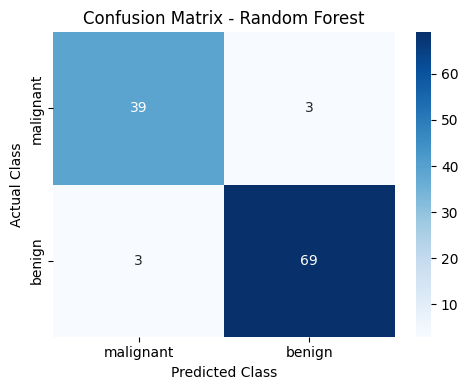


SVM
              precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        42
      benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



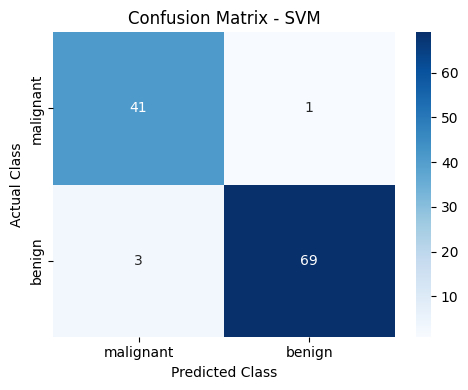


MODEL COMPARISON
        Model  Accuracy  Precision  Recall  F1 Score
Random Forest    0.9474     0.9583  0.9583    0.9583
          SVM    0.9649     0.9857  0.9583    0.9718


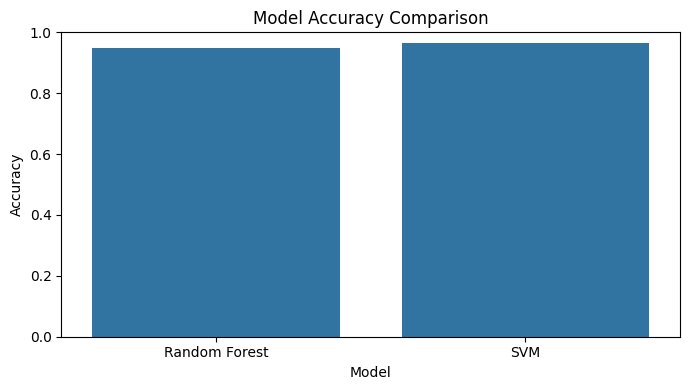


TOP 10 PREDICTIVE FEATURES
             Feature  Importance
     worst perimeter    0.143257
          worst area    0.130836
worst concave points    0.106208
 mean concave points    0.096277
        worst radius    0.082035
      mean concavity    0.052928
      mean perimeter    0.048060
         mean radius    0.045953
           mean area    0.042868
     worst concavity    0.042752


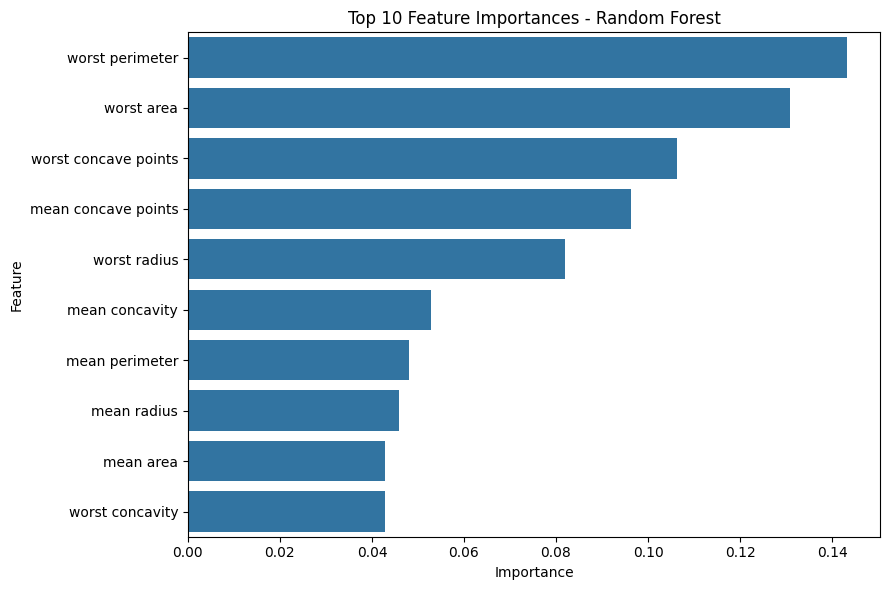


FINAL SUMMARY
Best model by test F1 score: SVM
Test F1 score: 0.9718
Test accuracy: 0.9649

Saved files:
1. model_performance.csv
2. feature_importance.csv


In [5]:

# Machine Learning for Genomic Data Classification
# Random Forest vs Support Vector Machine (SVM)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------
# 1. Load dataset
# ------------------------------------------------

dataset = load_breast_cancer(as_frame=True)

X = dataset.data
y = dataset.target

print("Dataset shape:", X.shape)
print("Feature names:")
print(X.columns.tolist())

print("\nTarget classes:")
print(dataset.target_names)
print("\nFirst five rows:")
print(X.head())

# ------------------------------------------------
# 2. Check missing values
# ------------------------------------------------

print("\nMissing values:", X.isnull().sum().sum())

# ------------------------------------------------
# 3. Split data into training and testing sets
# ------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# ------------------------------------------------
# 4. Build machine learning models
# ------------------------------------------------

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", class_weight="balanced")
    )
}

results = []
trained_models = {}

# ------------------------------------------------
# 5. Train and evaluate both models
# ------------------------------------------------

for name, model in models.items():

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

    print("\n", "=" * 45)
    print(name)
    print("=" * 45)

    print(classification_report(
        y_test,
        predictions,
        target_names=dataset.target_names,
        zero_division=0
    ))

    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=dataset.target_names,
        yticklabels=dataset.target_names
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 6. Compare model performance
# ------------------------------------------------

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print(results_df.round(4).to_string(index=False))

results_df.to_csv("model_performance.csv", index=False)

# Plot accuracy
plt.figure(figsize=(7, 4))
sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)
plt.ylim(0, 1)
plt.title("Model Accuracy Comparison")
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 7. Feature importance from Random Forest
# ------------------------------------------------

rf_model = trained_models["Random Forest"]

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nTOP 10 PREDICTIVE FEATURES")
print(importance_df.head(10).to_string(index=False))

importance_df.to_csv("feature_importance.csv", index=False)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)
plt.title("Top 10 Feature Importances - Random Forest")
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 8. Final summary
# ------------------------------------------------

best_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("\nFINAL SUMMARY")
print("Best model by test F1 score:", best_model["Model"])
print("Test F1 score:", round(best_model["F1 Score"], 4))
print("Test accuracy:", round(best_model["Accuracy"], 4))

print("\nSaved files:")
print("1. model_performance.csv")
print("2. feature_importance.csv")
